In [ ]:
# If you have a GPU runtime, this will show it:
!nvidia-smi

# Fresh installs
!pip -q install --upgrade pip
!pip -q install "transformers>=4.43" "accelerate>=0.33" "bitsandbytes>=0.43" \
                 sentencepiece safetensors huggingface_hub


Thu Aug 28 07:54:34 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   31C    P0             49W /  400W |     629MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

# New Section

In [ ]:
from huggingface_hub import login
# Paste your HF token when prompted (create from https://huggingface.co/settings/tokens)
login()


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto"
)

device = next(model.parameters()).device
print("Loaded (4-bit) on:", device)

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/878 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/1.46G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Loaded (4-bit) on: cuda:0


In [ ]:
import threading, time, sys

def keep_colab_alive(interval_sec=60):
    """Print a small heartbeat so Colab sees activity."""
    while True:
        # ‘flush’ forces the message to appear immediately
        print(f"⏰ still training {time.strftime('%H:%M:%S')}", flush=True)
        time.sleep(interval_sec)

# Start the daemon – it dies automatically when the notebook stops
threading.Thread(target=keep_colab_alive, daemon=True).start()

⏰ still training 07:55:34


In [ ]:
from google.colab import files
import pandas as pd
from sklearn.preprocessing import StandardScaler
# Step 1: Upload the CSV file
uploaded = files.upload()

Saving Standardized_Dataset.csv to Standardized_Dataset.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# === Reset saved runs (checkpoints + metrics) ===
import os, glob, shutil

# Resolve the same checkpoint dir your script uses
DRIVE_ROOT = "/content/drive/MyDrive"
CKPT_DIR = os.path.join(DRIVE_ROOT, "checkpoints") if os.path.isdir(DRIVE_ROOT) else "./checkpoints"
METRICS_LIVE = os.path.join(CKPT_DIR, "run_metrics_live.csv")

print("Checkpoint dir:", CKPT_DIR)

# --- Easiest: nuke the whole folder and recreate it ---
if os.path.isdir(CKPT_DIR):
    shutil.rmtree(CKPT_DIR)
os.makedirs(CKPT_DIR, exist_ok=True)

# --- Also remove any final metrics saved in the working dir ---
for f in ["run_metrics.csv", "run_metrics.parquet"]:
    if os.path.exists(f):
        os.remove(f)
        print("Removed:", f)

print("✔ All saved episodes/checkpoints cleared. Next run will start fresh.")


Checkpoint dir: /content/drive/MyDrive/checkpoints
Removed: run_metrics.csv
✔ All saved episodes/checkpoints cleared. Next run will start fresh.


📁 Using CSV: Standardized_Dataset.csv
✔ Using checkpoint dir: /content/drive/MyDrive/checkpoints


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

⏰ still training 12:33:34


Setting `pad_token_id` to `eos_token_id`:128009 for open-end generation.


🤖 LLM (4-bit) on: cuda:0
🧭 PrefSpec: PrefSpec(w_cost=1.0, w_comf=2.0, w_co2=1.0, w_peak=1.0, pmv_min=-0.2, pmv_max=0.2, co2_cap_kg_per_kwh=0.45, peak_start_h=14, peak_end_h=18, sp_min=21.0, sp_max=25.0, max_sp_step=0.3, max_light_step=15, light_step=5)
🔄 Resuming from /content/drive/MyDrive/checkpoints/ckpt_ep0008_autosave_step00095000.pt
⚠️ Skipping RNG restore: RNG state must be a torch.ByteTensor
💡 start_ep=9, end_ep=11, NUM_EPISODES=2, global_step=95000


/tmp/ipython-input-2992134180.py:857: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  else: torch.set_rng_state(torch.tensor(st, dtype=torch.uint8))


... (10 outputs left out)

💾 Saved checkpoint → /content/drive/MyDrive/checkpoints/ckpt_ep0010_autosave_step00107000.pt
  ↳ Ep 11/11 • Step 290/11711 • Global 107,000
⏰ still training 12:52:34
⏰ still training 12:53:34
💾 Saved checkpoint → /content/drive/MyDrive/checkpoints/ckpt_ep0010_autosave_step00108000.pt
  ↳ Ep 11/11 • Step 1290/11711 • Global 108,000
⏰ still training 12:54:34
💾 Saved checkpoint → /content/drive/MyDrive/checkpoints/ckpt_ep0010_autosave_step00109000.pt
  ↳ Ep 11/11 • Step 2290/11711 • Global 109,000
⏰ still training 12:55:34
⏰ still training 12:56:34
💾 Saved checkpoint → /content/drive/MyDrive/checkpoints/ckpt_ep0010_autosave_step00110000.pt
  ↳ Ep 11/11 • Step 3290/11711 • Global 110,000
⏰ still training 12:57:34
💾 Saved checkpoint → /content/drive/MyDrive/checkpoints/ckpt_ep0010_autosave_step00111000.pt
  ↳ Ep 11/11 • Step 4290/11711 • Global 111,000
⏰ still training 12:58:34
⏰ still training 12:59:34
💾 Saved checkpoint → /content/drive/MyDrive/checkpoints/ckpt_ep0010_autosave_step0011200

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️ Download triggered.


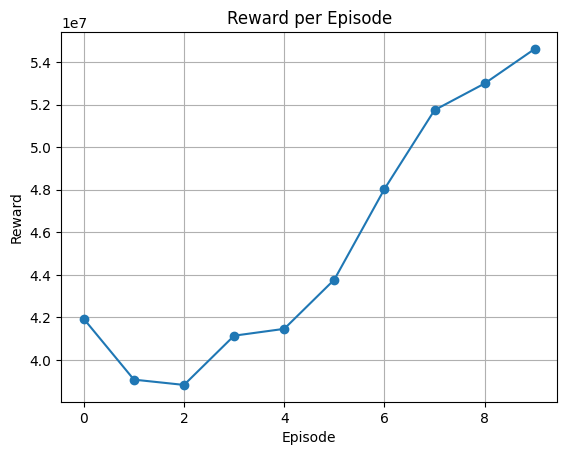

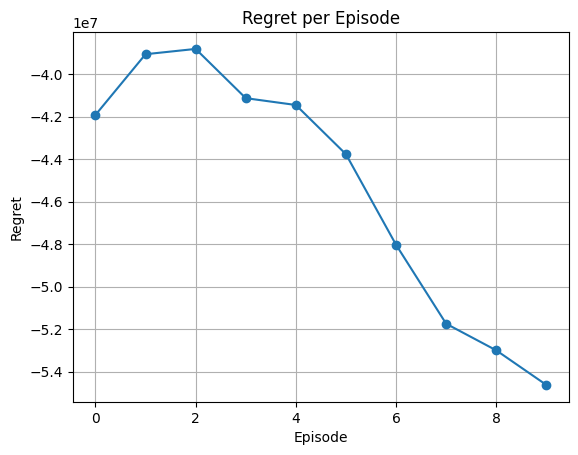

In [ ]:
# =============================================================
# MASAC + Transformer + Language→Reward/Constraint Compiler
# 3 Agents (HVAC, Lighting, PV-routing) + Battery physics
# HITL UI + optional LLM ICL suggestion (graceful fallback)
# Full KPIs (PV/Batt + MERLIN-like), progress bars, resumable
# =============================================================

# ===================== Colab deps (quiet) =====================
try:
    import google.colab  # type: ignore
    IN_COLAB = True
except Exception:
    IN_COLAB = False

if IN_COLAB:
    # re-run if needed
    !pip -q install --upgrade pip
    !pip -q install "transformers>=4.43" "accelerate>=0.33" "bitsandbytes>=0.43" \
                     sentencepiece safetensors huggingface_hub tqdm

# ============================ CONFIG ==========================
CONFIG = dict(
    # episodes / logging
    NUM_EPISODES    = 10,
    LOG_EVERY       = 1000,
    SHOW_PROGRESS   = True,
    RESUME          = True,     # <- resume automatically if checkpoints exist
    CKPT_AUTOSAVE_STEPS = 1000, # <- mid-episode autosave frequency (steps)

    # SAC
    TAU             = 0.01,
    GAMMA           = 0.99,
    ACTOR_LR        = 3e-4,
    CRITIC_LR       = 1e-3,
    ALPHA_LR        = 3e-4,
    BATCH_SIZE      = 256,
    BUFFER_SIZE     = 100_000,

    # Temporal encoder / attention
    EMBED_DIM       = 96,
    NUM_HEADS       = 4,
    NUM_LAYERS      = 2,
    SEQ_LEN         = 8,
    TEMP_DIM        = 64,

    # Env/action defaults (may be overridden by PrefSpec)
    HVAC_MIN        = 21.0,
    HVAC_MAX        = 25.0,
    PMV_MIN         = -0.5,
    PMV_MAX         =  0.5,

    # Preferences: free-form text → compiler
    PREF_TEXT = (
        """
        Keep PMV tight (±0.25) during meetings; minimize peaks 14:00–18:00;
        CO2 under 0.45 kg/kWh; allow 21–25 °C; no change >0.3°C per step;
        comfort is very important; minimize CO2; prioritize PV self-consumption.
        """
    ),

    # LLM (4-bit, ephemeral — auto-disables if OOM)
    LLM_ENABLED     = True,
    LLM_MODEL_ID    = "meta-llama/Llama-3.2-3B-Instruct",
    ICL_MAX_SHOTS   = 4,
    LLM_MAX_NEW_TOK = 64,
    LLM_TEMPERATURE = 0.08,

    # UI timeout (sec) — on timeout defaults to LLM suggestion (or policy)
    UI_TIMEOUT_S    = 60,

    # data path (auto-resolve if None)
    CSV_PATH        = None,
)

# ===================== CUDA alloc conf BEFORE torch =====================
import os as _os
_os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

# =============================== Imports ===============================
import os, gc, glob, json, re, time, random
from dataclasses import dataclass
from collections import deque, namedtuple
from typing import Dict, Any, List, Optional

import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.distributions import Normal
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

try:
    from google.colab import output as colab_output  # type: ignore
    _HAS_COLAB = True
except Exception:
    _HAS_COLAB = False

# ============================ CSV resolver =============================
def _resolve_csv_path():
    # explicit
    p = CONFIG.get("CSV_PATH")
    if p and os.path.exists(str(p)):
        return str(p)

    # common upload path (your file)
    for cand in ["/mnt/data/TAC-MADRL-PV.csv"]:
        if os.path.exists(cand):
            return cand

    # files.upload() dict
    if "uploaded" in globals():
        try:
            for k in uploaded.keys():
                if k.lower().endswith(".csv"):
                    return k
        except Exception:
            pass

    # first CSV in CWD
    csvs = sorted(glob.glob("*.csv"))
    if csvs:
        return csvs[0]

    raise FileNotFoundError("No CSV found. Upload one or set CONFIG['CSV_PATH'].")

CSV_PATH = _resolve_csv_path()
print("📁 Using CSV:", CSV_PATH)

# ============================ Derived globals ==========================
TAU, GAMMA = CONFIG["TAU"], CONFIG["GAMMA"]
ACTOR_LR, CRITIC_LR, ALPHA_LR = CONFIG["ACTOR_LR"], CONFIG["CRITIC_LR"], CONFIG["ALPHA_LR"]
BATCH_SIZE, BUFFER_SIZE = CONFIG["BATCH_SIZE"], CONFIG["BUFFER_SIZE"]
EMBED_DIM, NUM_HEADS, NUM_LAYERS = CONFIG["EMBED_DIM"], CONFIG["NUM_HEADS"], CONFIG["NUM_LAYERS"]
SEQ_LEN, TEMP_DIM = CONFIG["SEQ_LEN"], CONFIG["TEMP_DIM"]
HVAC_MIN, HVAC_MAX, PMV_MIN, PMV_MAX = CONFIG["HVAC_MIN"], CONFIG["HVAC_MAX"], CONFIG["PMV_MIN"], CONFIG["PMV_MAX"]

LLM_ENABLED = bool(CONFIG.get("LLM_ENABLED", False))
MODEL_ID    = str(CONFIG.get("LLM_MODEL_ID", ""))

DRIVE_ROOT = "/content/drive/MyDrive"
CKPT_DIR   = os.path.join(DRIVE_ROOT, "checkpoints") if os.path.isdir(DRIVE_ROOT) else "./checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)
METRICS_LIVE = os.path.join(CKPT_DIR, "run_metrics_live.csv")
print("✔ Using checkpoint dir:", CKPT_DIR)

EPS = 1e-6
ACTION_DIM, N_AGENTS = 1, 3    # HVAC, Lighting, PV-routing

# HVAC–comfort/energy coupling
HVAC_SETPOINT_BASE = 23.0
COOL_SENSITIVITY   = 0.12
PMV_PER_DEG        = 0.15
COOL_CLAMP_MIN     = 0.30
COOL_CLAMP_MAX     = 1.20

# ===== PV + Battery constants =====
PV_MONTHLY_KWH = {}   # e.g. {5:2.09,6:2.17,7:2.09,8:1.98} to synthesize PV if dataset lacks it
PV_HOURLY_SHAPE = {}  # month -> 24-hour shape list
MONTHS_SUBSET  = None # e.g. [5,6,7,8] to subset dataset months

BATT_CAP_KWH    = 19.0
BATT_SOC_MAX    = 0.97
BATT_SOC_MIN    = 0.05
BATT_EFF_CH     = 0.95
BATT_EFF_DCH    = 0.95
BATT_MAX_C_RATE = 1.0/7.0
BATT_MAX_D_RATE = 1.0/4.0
BATT_MAX_CHARGE_KW = 15.0
STEP_HOURS      = 1.0
SELL_TARIFF_FIXED = 3820.0

# =============================================================
# Language → Reward/Constraint Compiler
# =============================================================
@dataclass
class PrefSpec:
    # Weights
    w_cost:  float = 1.0
    w_comf:  float = 1.0
    w_co2:   float = 0.0
    w_peak:  float = 0.0
    # Comfort band
    pmv_min: float = PMV_MIN
    pmv_max: float = PMV_MAX
    # CO₂ cap
    co2_cap_kg_per_kwh: Optional[float] = None
    # Peak window [h_start, h_end)
    peak_start_h: Optional[int] = None
    peak_end_h:   Optional[int] = None
    # Bounds & ramps
    sp_min: float = HVAC_MIN
    sp_max: float = HVAC_MAX
    max_sp_step: float = 0.5
    max_light_step: int = 15
    light_step: int = 5

# ------- Optional LLM ICL plumbing (safe fallback) -------
_tokenizer = _model = _device = None

def _load_llm_4bit(model_id: str):
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
    bnb = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16
    )
    tok = AutoTokenizer.from_pretrained(model_id, use_fast=True)
    mdl = AutoModelForCausalLM.from_pretrained(
        model_id, quantization_config=bnb, device_map="auto",
        low_cpu_mem_usage=True, attn_implementation="sdpa",
    )
    mdl.config.use_cache = False
    mdl.eval()
    dev = next(mdl.parameters()).device
    print(f"🤖 LLM (4-bit) on: {dev}")
    return tok, mdl, dev

def _with_ephemeral_llm():
    global _tokenizer, _model, _device, LLM_ENABLED
    if not LLM_ENABLED:
        return
    if _model is None:
        try:
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            _tokenizer, _model, _device = _load_llm_4bit(MODEL_ID)
        except Exception as e:
            print(f"⚠️ 4-bit LLM load failed: {e}\n   → Disabling LLM suggestions and continuing.")
            _tokenizer = _model = _device = None
            LLM_ENABLED = False

def _free_llm():
    global _tokenizer, _model, _device
    try:
        del _model; del _tokenizer
    except Exception:
        pass
    _tokenizer = _model = _device = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def _chat(messages, max_new_tokens=CONFIG["LLM_MAX_NEW_TOK"], temperature=CONFIG["LLM_TEMPERATURE"], top_p=0.9):
    if not LLM_ENABLED or _model is None:
        return ""
    prompt = _tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = _tokenizer(prompt, return_tensors="pt").to(_device)
    with torch.no_grad():
        out = _model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=True,
            temperature=temperature, top_p=top_p, eos_token_id=_tokenizer.eos_token_id,
        )
    gen = out[0][inputs["input_ids"].shape[1]:]
    return _tokenizer.decode(gen, skip_special_tokens=True)

def _extract_json(text: str) -> Dict[str, Any]:
    s, e = text.find("{"), text.rfind("}")
    if s == -1 or e == -1 or e <= s:
        raise ValueError("No JSON in text.")
    return json.loads(text[s:e+1])

def compile_prefs_from_text(text: str, llm_fallback=True) -> PrefSpec:
    """Deterministic regex parsing; optional LLM fill for ambiguous bits."""
    spec = PrefSpec()

    # PMV band: "[-0.2, 0.2]" or "±0.25"
    m = re.search(r'pmv[^0-9\-+]*\[?([\-+]?\d*\.?\d)\s*,\s*([\-+]?\d*\.?\d)\]?', text, re.I)
    if m:
        try:
            spec.pmv_min, spec.pmv_max = float(m.group(1)), float(m.group(2))
        except Exception:
            pass
    m = re.search(r'pmv[^0-9]*±\s*(\d*\.?\d)', text, re.I)
    if m:
        w = float(m.group(1)); spec.pmv_min, spec.pmv_max = -w, w

    # CO2 cap: "under 0.45 kg/kWh"
    m = re.search(r'co2[^0-9]*under[^0-9]*([\d\.]+)\s*kg\s*/\s*kwh', text, re.I)
    if m:
        spec.co2_cap_kg_per_kwh = float(m.group(1))

    # Peak window: "14:00–18:00" or "14-18"
    m = re.search(r'(?:peak|peaks?)\D*([01]?\d|2[0-3])(?::?\d\d)?\s*[–\-]\s*([01]?\d|2[0-3])', text, re.I)
    if m:
        spec.peak_start_h, spec.peak_end_h = int(m.group(1)), int(m.group(2))

    # Weights hints
    if re.search(r'comfort (is|as) (very )?important|keep pmv tight', text, re.I): spec.w_comf = 2.0
    if re.search(r'minimi[sz]e (co2|carbon)|co2 under', text, re.I): spec.w_co2 = 1.0
    if re.search(r'minimi[sz]e peaks?', text, re.I): spec.w_peak = 1.0

    # Setpoint bounds and ramp
    m = re.search(r'(\d{2}(?:\.\d)?)\s*[–\-]\s*(\d{2}(?:\.\d)?)\s*°?c', text, re.I)
    if m:
        spec.sp_min, spec.sp_max = float(m.group(1)), float(m.group(2))
    m = re.search(r'no change[^0-9]*>\s*([\d\.]+)\s*°?c', text, re.I)
    if m:
        spec.max_sp_step = float(m.group(1))

    # Optional LLM refinement
    if llm_fallback and LLM_ENABLED:
        _with_ephemeral_llm()
        try:
            schema = {
                "type": "object",
                "properties": {
                    "w_cost": {"type": "number"},
                    "w_comf": {"type": "number"},
                    "w_co2":  {"type": "number"},
                    "w_peak": {"type": "number"},
                    "pmv_min": {"type": "number"},
                    "pmv_max": {"type": "number"},
                    "co2_cap_kg_per_kwh": {"type": ["number","null"]},
                    "peak_start_h": {"type": ["integer","null"]},
                    "peak_end_h":   {"type": ["integer","null"]},
                    "sp_min": {"type": "number"},
                    "sp_max": {"type": "number"},
                    "max_sp_step": {"type": "number"},
                    "max_light_step": {"type": "integer"},
                    "light_step": {"type": "integer"}
                },
                "additionalProperties": False
            }
            sys = ("Extract a JSON object that fits this schema: " + json.dumps(schema) +
                   ". Fill N/A with null. Prefer conservative defaults for safety.")
            msg = [{"role": "system", "content": sys}, {"role": "user", "content": text}]
            out = _chat(msg, temperature=0.0, top_p=0.0)
            if out:
                js = _extract_json(out)
                for k, v in js.items():
                    if hasattr(spec, k) and v is not None:
                        cur = getattr(spec, k)
                        setattr(spec, k, type(cur)(v))
        except Exception:
            pass
        finally:
            _free_llm()
    return spec

# =============================================================
# Environment (3 agents + Battery)
# =============================================================
class DatasetEnv:
    """
    Three agents: HVAC setpoint (°C), Lighting scale (0..1), PV surplus routing (0..1 → charge vs export).
    Priority: PV → load; PV surplus split by PV agent (charge vs export). If PV < load, auto-discharge battery; grid covers rest.
    Needs 'Date'; expects 'Cooling ', 'Fans', ' Pumps', 'Lighting'.
    Optional: 'Tariff' (or infer from 'Cost'), 'Sell_Tariff', 'Grid_CO2', PV cols ['PV_kWh','PV','PV_gen','PV Generation'].
    Reward uses PrefSpec: cost + comfort + co2(imports) + peak(imports).
    """
    def __init__(self, csv: str, pref_spec: Optional[PrefSpec] = None):
        self.pref = pref_spec or PrefSpec()
        df = pd.read_csv(csv, parse_dates=['Date'])

        # Optional month filter
        if MONTHS_SUBSET is not None:
            df = df[df['Date'].dt.month.isin(MONTHS_SUBSET)].reset_index(drop=True)

        # time features
        dt   = df['Date']
        hour = dt.dt.hour + dt.dt.minute/60.0
        dow  = dt.dt.dayofweek
        mon  = dt.dt.month
        df['tod_sin'] = np.sin(2*np.pi*hour/24.0)
        df['tod_cos'] = np.cos(2*np.pi*hour/24.0)
        df['dow_sin'] = np.sin(2*np.pi*dow/7.0)
        df['dow_cos'] = np.cos(2*np.pi*dow/7.0)
        df['mon_sin'] = np.sin(2*np.pi*(mon-1)/12.0)
        df['mon_cos'] = np.cos(2*np.pi*(mon-1)/12.0)
        df['is_weekend'] = (dow>=5).astype(np.float32)

        # robust median tariff fallback
        def baseline_energy_row(r):
            return float(r.get('Cooling ',0.0))+float(r.get('Fans',0.0))+float(r.get(' Pumps',0.0))+float(r.get('Lighting',0.0))
        if 'Tariff' in df.columns and df['Tariff'].notna().any():
            self.median_tariff = float(pd.to_numeric(df['Tariff'], errors='coerce').dropna().median())
        else:
            valid = []
            for _, r in df.iterrows():
                be = baseline_energy_row(r)
                if be > 1e-6:
                    valid.append(float(r.get('Cost',0.0))/be)
            self.median_tariff = float(np.median(valid)) if len(valid) else 0.0

        self.df       = df.reset_index(drop=True)
        self.obs_cols = [c for c in self.df.columns if c != 'Date']
        self.obs_dim  = len(self.obs_cols) + 1   # + SOC fraction
        self.n        = len(self.df)
        self.idx      = 0

        # Pref/bounds
        self.pmv_min = float(self.pref.pmv_min)
        self.pmv_max = float(self.pref.pmv_max)
        self.sp_min  = float(self.pref.sp_min)
        self.sp_max  = float(self.pref.sp_max)
        self.max_sp_step = float(self.pref.max_sp_step)
        self.max_light_step = int(self.pref.max_light_step)
        self.light_step = int(self.pref.light_step)

        # Battery state (kWh)
        self.soc_kwh = BATT_CAP_KWH * max(min(0.50, BATT_SOC_MAX), BATT_SOC_MIN)

        # PV helpers
        self._pv_keys = ['PV_kWh','PV','PV_gen','PV Generation']
        self._pv_override = None
        if PV_MONTHLY_KWH:
            dates = self.df['Date']
            pv_vec = np.zeros(len(self.df), dtype=float)
            for m, total_kwh in PV_MONTHLY_KWH.items():
                mask_m = (dates.dt.month == m)
                if not mask_m.any(): continue
                days_m = dates[mask_m].dt.normalize().nunique()
                if days_m == 0: continue
                shape = np.array(PV_HOURLY_SHAPE.get(m, np.zeros(24)), dtype=float)
                if shape.size != 24: raise ValueError(f"PV_HOURLY_SHAPE[{m}] must have 24 values.")
                w = shape / max(shape.sum(), 1e-9)
                per_day = total_kwh / days_m
                hours = dates.dt.hour.values
                idxs  = np.where(mask_m.values)[0]
                pv_vec[idxs] = per_day * w[hours[idxs]]
            self._pv_override = pv_vec

    def _row_obs(self, i):
        row = self.df.loc[i, self.obs_cols].values.astype(np.float32)
        soc = np.array([self.soc_kwh / BATT_CAP_KWH], dtype=np.float32)
        return np.concatenate([row, soc], axis=0)

    def reset(self):
        self.idx = 0
        self.soc_kwh = BATT_CAP_KWH * max(min(0.50, BATT_SOC_MAX), BATT_SOC_MIN)
        obs_vec = self._row_obs(self.idx)
        obs     = np.tile(obs_vec, (N_AGENTS, 1))
        return obs, self.df.loc[self.idx, 'Date']

    def _pv_from_row_or_override(self, i, row):
        for k in self._pv_keys:
            if k in row and pd.notna(row[k]):
                try: return float(row[k])
                except: pass
        if self._pv_override is not None:
            return float(self._pv_override[i])
        return 0.0

    def step(self, hvac_sp: float, light_act: float, pv_charge_frac: float):
        self.idx += 1
        done  = self.idx >= self.n - 1
        row   = self.df.loc[self.idx]
        date  = row['Date']

        # Base loads from dataset
        cooling0 = float(row.get('Cooling ', 0.0))
        fans     = float(row.get('Fans', 0.0))
        pumps    = float(row.get(' Pumps', 0.0))
        light0   = float(row.get('Lighting', 0.0))

        # Enforce setpoint bounds, adjust cooling
        sp = float(np.clip(hvac_sp, self.sp_min, self.sp_max))
        delta_sp   = sp - HVAC_SETPOINT_BASE
        cool_scale = np.clip(1.0 - COOL_SENSITIVITY * delta_sp, COOL_CLAMP_MIN, COOL_CLAMP_MAX)
        cooling    = cool_scale * cooling0

        # Lighting
        a_light   = float(np.clip(light_act, 0.0, 1.0))
        light_kwh = a_light * light0

        # Tariffs
        baseline_energy = cooling0 + fans + pumps + light0
        if baseline_energy > 1e-8:
            tariff = float(row.get('Tariff', row.get('Cost', 0.0)/baseline_energy))
        else:
            tariff = float(row.get('Tariff', self.median_tariff))
        sell_tariff = float(row.get('Sell_Tariff', SELL_TARIFF_FIXED))
        grid_co2    = float(row.get('Grid_CO2', 0.4))  # kg/kWh

        # Raw building load (kWh)
        gross_load = cooling + fans + pumps + light_kwh

        # PV available (kWh)
        pv_kwh       = self._pv_from_row_or_override(self.idx, row)
        pv_to_load   = min(pv_kwh, gross_load)
        resid_load   = gross_load - pv_to_load
        pv_surplus   = max(pv_kwh - pv_to_load, 0.0)

        # PV surplus split by PV agent (charge vs export)
        a_pv = float(np.clip(pv_charge_frac, 0.0, 1.0))
        soc_cap_kwh   = BATT_CAP_KWH * BATT_SOC_MAX
        soc_min_kwh   = BATT_CAP_KWH * BATT_SOC_MIN
        batt_room_in  = max(soc_cap_kwh - self.soc_kwh, 0.0)

        rate_lim_kwh  = BATT_MAX_C_RATE * BATT_CAP_KWH * STEP_HOURS
        power_lim_kwh = BATT_MAX_CHARGE_KW * STEP_HOURS
        max_charge_in = min(rate_lim_kwh, power_lim_kwh)

        req_charge_in = a_pv * pv_surplus
        feas_charge_in= min(req_charge_in, pv_surplus, max_charge_in, batt_room_in/max(BATT_EFF_CH,1e-9))
        batt_gain     = feas_charge_in * BATT_EFF_CH
        self.soc_kwh  = min(self.soc_kwh + batt_gain, soc_cap_kwh)
        export_kwh    = max(pv_surplus - feas_charge_in, 0.0)

        # Auto-discharge to cover resid load
        avail_dch_in   = max(self.soc_kwh - soc_min_kwh, 0.0)
        d_rate_lim_in  = BATT_MAX_D_RATE * BATT_CAP_KWH * STEP_HOURS
        d_feasible_in  = min(avail_dch_in, d_rate_lim_in)
        deliverable_out= d_feasible_in * BATT_EFF_DCH

        use_batt_out   = min(resid_load, deliverable_out)
        use_batt_in    = use_batt_out / max(BATT_EFF_DCH,1e-9)
        self.soc_kwh  -= use_batt_in
        resid_load    -= use_batt_out

        # Grid and cost (imports cost; exports earn)
        grid_import = max(resid_load, 0.0)
        grid_export = export_kwh
        step_cost   = tariff * grid_import - sell_tariff * grid_export

        # Comfort penalty
        pmv     = row.get('Fanger PMV', row.get('PMV', 0.0))
        pmv     = float(pmv) + PMV_PER_DEG * delta_sp
        penalty = max(pmv - self.pmv_max, 0) + max(self.pmv_min - pmv, 0)

        # Reward terms (weighted)
        w = self.pref
        co2_term  = grid_co2 * grid_import
        peak_term = 0.0
        if (self.pref.peak_start_h is not None) and (self.pref.peak_end_h is not None):
            h = int(date.hour)
            if int(self.pref.peak_start_h) <= h < int(self.pref.peak_end_h):
                peak_term = grid_import
        reward = -(w.w_cost*step_cost + w.w_comf*penalty + w.w_co2*co2_term + w.w_peak*peak_term)

        # Next obs
        obs_vec = self._row_obs(self.idx)
        obs     = np.tile(obs_vec, (N_AGENTS, 1))

        # Info logging (for KPIs)
        info = {**row.drop(labels=['Date']).to_dict(), 'date': date}
        info['Cooling ']            = cooling
        info['Lighting']            = light_kwh
        info['Light_scale']         = a_light
        info['Cost']                = step_cost
        info['Tariff']              = tariff
        info['Sell_Tariff']         = sell_tariff
        info['Grid_CO2']            = grid_co2
        info['Fanger PMV']          = pmv
        info['PMV_violation']       = penalty  # keep both names
        info['Penalty']             = penalty

        # PV/Battery flows
        info['PV_gen']              = pv_kwh
        info['PV_to_load_kWh']      = pv_to_load
        info['PV_to_batt_in_kWh']   = feas_charge_in
        info['Batt_ch_gain_kWh']    = batt_gain
        info['Batt_dch_out_kWh']    = use_batt_out
        info['Batt_SOC']            = self.soc_kwh / BATT_CAP_KWH

        # Grid flows + net for MERLIN-like KPIs
        info['Grid_import']         = grid_import
        info['Grid_export']         = grid_export
        info['Net_kWh']             = grid_import - grid_export
        info['Net_kWh_district']    = info['Net_kWh']

        # Reward breakdown
        info['Reward_terms'] = {
            'cost': step_cost, 'pmv_violation': penalty,
            'co2_term': co2_term, 'peak_term': peak_term,
            'weights': {'w_cost': w.w_cost, 'w_comf': w.w_comf, 'w_co2': w.w_co2, 'w_peak': w.w_peak}
        }
        return obs, reward, done, info

# =============================================================
# Replay Buffer
# =============================================================
Transition = namedtuple('T', ('obs','act','rew','nxt','done','seq','nseq'))
class ReplayBuffer:
    def __init__(self, cap): self.buf = deque(maxlen=cap)
    def push(self,*a):       self.buf.append(Transition(*a))
    def sample(self,b):      return random.sample(self.buf,b)
    def __len__(self):       return len(self.buf)

# =============================================================
# Temporal Encoder (Transformer)
# =============================================================
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=4096):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0), persistent=False)
    def forward(self, x):  # [B,L,D]
        return x + self.pe[:, :x.size(1)]

class TemporalEncoder(nn.Module):
    def __init__(self, input_dim, model_dim=TEMP_DIM, nhead=NUM_HEADS, num_layers=NUM_LAYERS):
        super().__init__()
        self.proj = nn.Linear(input_dim, model_dim)
        self.pos  = PositionalEncoding(model_dim, max_len=4096)
        enc = nn.TransformerEncoderLayer(d_model=model_dim, nhead=nhead,
                                         dim_feedforward=4*model_dim, activation='gelu',
                                         batch_first=True)
        self.tr = nn.TransformerEncoder(enc, num_layers=num_layers)
    def forward(self, seq):
        x = self.proj(seq)
        x = self.pos(x)
        x = self.tr(x)
        return x[:, -1, :]

# =============================================================
# Per-timestep Attention
# =============================================================
class MultiHeadAttention(nn.Module):
    def __init__(self, inp_dim, emb_dim, heads):
        super().__init__()
        assert emb_dim % heads == 0
        self.h = heads; self.hd = emb_dim // heads; self.scale = self.hd ** -0.5
        self.q_proj = nn.Linear(inp_dim, emb_dim)
        self.k_proj = nn.Linear(inp_dim, emb_dim)
        self.v_proj = nn.Linear(inp_dim, emb_dim)
        self.out    = nn.Linear(emb_dim, emb_dim)
    def forward(self, x):  # x: [B,N,TOKEN_DIM]
        B, N, _ = x.shape
        q = self.q_proj(x).view(B, self.h, N, self.hd)
        k = self.k_proj(x).view(B, self.h, N, self.hd)
        v = self.v_proj(x).view(B, self.h, N, self.hd)
        scores = (q @ k.transpose(-2, -1)) * self.scale
        w = F.softmax(scores, dim=-1)
        attn = (w @ v).transpose(1, 2).reshape(B, N, -1)
        return self.out(attn)

# =============================================================
# Actors / Critic
# =============================================================
def clamp_logstd(x): return x.clamp(-20,2)

class BaseActor(nn.Module):
    def __init__(self, obs_dim, ctx_dim=TEMP_DIM, embed_dim=EMBED_DIM, heads=NUM_HEADS,
                 token_index=0, squasher='tanh'):
        super().__init__()
        self.embed = nn.Linear(obs_dim, embed_dim)
        self.ctx_p = nn.Linear(ctx_dim, embed_dim)
        self.attn  = MultiHeadAttention(embed_dim, embed_dim, heads)
        self.mlp   = nn.Sequential(nn.Linear(embed_dim,256),nn.ReLU(),
                                   nn.Linear(256,256),nn.ReLU())
        self.mu      = nn.Linear(256,1)
        self.log_std = nn.Linear(256,1)
        self.token_index = token_index
        self.squasher = squasher
    def forward(self, o, ctx):
        x = self.embed(o) + self.ctx_p(ctx).unsqueeze(1)
        x = self.attn(x)
        h = self.mlp(x[:, self.token_index])
        mu, log_std = self.mu(h), clamp_logstd(self.log_std(h))
        return mu, log_std.exp()
    def sample(self, o, ctx):
        mu, std = self(o, ctx)
        dist = Normal(mu, std)
        z = dist.rsample()
        if self.squasher == 'tanh':         # HVAC setpoint
            r  = torch.tanh(z)
            a  = HVAC_MIN + (r + 1.0) * 0.5 * (HVAC_MAX - HVAC_MIN)
            logp = dist.log_prob(z) - torch.log(1 - r.pow(2) + EPS)
        else:                               # Lighting / PV
            a  = torch.sigmoid(z)
            logp = dist.log_prob(z) - torch.log(a*(1 - a) + EPS)
        return a, logp

class HVACActor(BaseActor):
    def __init__(self, obs_dim, ctx_dim=TEMP_DIM, embed_dim=EMBED_DIM, heads=NUM_HEADS):
        super().__init__(obs_dim, ctx_dim, embed_dim, heads, token_index=0, squasher='tanh')

class LightingActor(BaseActor):
    def __init__(self, obs_dim, ctx_dim=TEMP_DIM, embed_dim=EMBED_DIM, heads=NUM_HEADS):
        super().__init__(obs_dim, ctx_dim, embed_dim, heads, token_index=1, squasher='sigmoid')

class PVActor(BaseActor):
    def __init__(self, obs_dim, ctx_dim=TEMP_DIM, embed_dim=EMBED_DIM, heads=NUM_HEADS):
        super().__init__(obs_dim, ctx_dim, embed_dim, heads, token_index=2, squasher='sigmoid')

class Critic(nn.Module):
    def __init__(self, obs_dim, ctx_dim=TEMP_DIM, embed_dim=EMBED_DIM, heads=NUM_HEADS):
        super().__init__()
        self.oembed, self.aembed = nn.Linear(obs_dim,embed_dim), nn.Linear(1,embed_dim)
        self.ctx_p = nn.Linear(ctx_dim, embed_dim*2)
        self.attn  = MultiHeadAttention(embed_dim*2, embed_dim*2, heads)
        self.q     = nn.Sequential(nn.Linear(embed_dim*2*N_AGENTS,256),nn.ReLU(),
                                   nn.Linear(256,256),nn.ReLU(),nn.Linear(256,1))
    def forward(self, o, a, ctx):
        x = torch.cat([self.oembed(o), self.aembed(a)], -1) + self.ctx_p(ctx).unsqueeze(1)
        x = self.attn(x)
        return self.q(x.view(x.size(0),-1))

# =============================================================
# SAC Agent (centralized training, centralized execution)
# =============================================================
class MultiAgentSAC:
    def __init__(self, obs_dim, device='cpu'):
        self.device = device
        self.tau, self.gamma = TAU, GAMMA
        self.batch = BATCH_SIZE
        self.buf   = ReplayBuffer(BUFFER_SIZE)

        self.temporal = TemporalEncoder(obs_dim, model_dim=TEMP_DIM, nhead=NUM_HEADS, num_layers=NUM_LAYERS).to(device)
        self.actors   = nn.ModuleList([
            HVACActor(obs_dim, TEMP_DIM, EMBED_DIM, NUM_HEADS),
            LightingActor(obs_dim, TEMP_DIM, EMBED_DIM, NUM_HEADS),
            PVActor(obs_dim, TEMP_DIM, EMBED_DIM, NUM_HEADS),
        ]).to(device)
        self.critic1  = Critic(obs_dim, TEMP_DIM, EMBED_DIM, NUM_HEADS).to(device)
        self.critic2  = Critic(obs_dim, TEMP_DIM, EMBED_DIM, NUM_HEADS).to(device)
        self.targ1    = Critic(obs_dim, TEMP_DIM, EMBED_DIM, NUM_HEADS).to(device)
        self.targ2    = Critic(obs_dim, TEMP_DIM, EMBED_DIM, NUM_HEADS).to(device)
        self.targ1.load_state_dict(self.critic1.state_dict())
        self.targ2.load_state_dict(self.critic2.state_dict())

        self.log_alpha = torch.tensor(0.0, requires_grad=True, device=device)
        self.aopt   = torch.optim.Adam(self.actors.parameters(), lr=ACTOR_LR)
        self.copt   = torch.optim.Adam(
            list(self.critic1.parameters()) +
            list(self.critic2.parameters()) +
            list(self.temporal.parameters()),
            lr=CRITIC_LR
        )
        self.alopt  = torch.optim.Adam([self.log_alpha], lr=ALPHA_LR)
        self.target_ent = -ACTION_DIM * N_AGENTS

    @property
    def alpha(self): return torch.exp(self.log_alpha)

    def _update_target(self):
        for tgt, src in ((self.targ1, self.critic1), (self.targ2, self.critic2)):
            for tp, sp in zip(tgt.parameters(), src.parameters()):
                tp.data.copy_(self.tau * sp.data + (1 - self.tau) * tp.data)

    def store(self, *args): self.buf.push(*args)

    def train_step(self):
        if len(self.buf) < self.batch: return
        batch = self.buf.sample(self.batch)
        dev = self.device

        obs = torch.stack([torch.tensor(x.obs, dtype=torch.float32, device=dev) for x in batch])
        act = torch.stack([torch.tensor(x.act, dtype=torch.float32, device=dev) for x in batch]).unsqueeze(-1)
        rew = torch.tensor([x.rew for x in batch], dtype=torch.float32, device=dev).unsqueeze(1)
        nxt = torch.stack([torch.tensor(x.nxt, dtype=torch.float32, device=dev) for x in batch])
        don = torch.tensor([x.done for x in batch], dtype=torch.float32, device=dev).unsqueeze(1)
        oseq = torch.stack([torch.tensor(x.seq,  dtype=torch.float32, device=dev) for x in batch])
        nseq = torch.stack([torch.tensor(x.nseq, dtype=torch.float32, device=dev) for x in batch])

        ctx  = self.temporal(oseq)
        nctx = self.temporal(nseq)

        with torch.no_grad():
            nas, lps = [], []
            for ac in self.actors:
                a, lp = ac.sample(nxt, nctx)
                nas.append(a); lps.append(lp)
            nas = torch.stack(nas, 1)
            lps = torch.stack(lps, 1).sum(dim=1)
            q1t = self.targ1(nxt, nas, nctx)
            q2t = self.targ2(nxt, nas, nctx)
            tgt = rew + (1 - don) * self.gamma * (torch.min(q1t, q2t) - self.alpha * lps)

        q1 = self.critic1(obs, act, ctx)
        q2 = self.critic2(obs, act, ctx)
        closs = F.mse_loss(q1, tgt) + F.mse_loss(q2, tgt)
        self.copt.zero_grad(); closs.backward(); self.copt.step()

        ctx_pi = ctx.detach()
        nas, lps = [], []
        for ac in self.actors:
            a, lp = ac.sample(obs, ctx_pi)
            nas.append(a); lps.append(lp)
        nas  = torch.stack(nas, 1)
        lps  = torch.stack(lps, 1).sum(1, keepdim=True)
        q1pi = self.critic1(obs, nas, ctx_pi)
        q2pi = self.critic2(obs, nas, ctx_pi)
        aloss = (self.alpha * lps - torch.min(q1pi, q2pi)).mean()
        self.aopt.zero_grad(); aloss.backward(); self.aopt.step()

        tloss = -(self.log_alpha * (lps + self.target_ent).detach()).mean()
        self.alopt.zero_grad(); tloss.backward(); self.alopt.step()

        self._update_target()

# =============================================================
# Checkpoints (safe RNG handling)
# =============================================================
def _np_state_serialize():
    st = np.random.get_state()
    return (st[0], st[1].tolist(), st[2], st[3], st[4])

def _np_state_restore(st):
    if isinstance(st[1], list):
        st = (st[0], np.array(st[1], dtype=np.uint32), st[2], st[3], st[4])
    np.random.set_state(st)

def save_ckpt(ep, global_step, env, agent, fname=None, save_buffer=False):
    if fname is None:
        fname = f"ckpt_ep{ep:04d}_step{global_step:08d}.pt"
    path = os.path.join(CKPT_DIR, fname)
    ckpt = {
        "episode": ep,
        "global_step": global_step,
        "env_idx": getattr(env, "idx", 0),
        "actors":  agent.actors.state_dict(),
        "critic1": agent.critic1.state_dict(),
        "critic2": agent.critic2.state_dict(),
        "targ1":   agent.targ1.state_dict(),
        "targ2":   agent.targ2.state_dict(),
        "temporal": agent.temporal.state_dict(),
        "aopt":  agent.aopt.state_dict(),
        "copt":  agent.copt.state_dict(),
        "alopt": agent.alopt.state_dict(),
        "log_alpha": float(agent.log_alpha.detach().cpu()),
        "rng_torch": torch.get_rng_state(),
        "rng_python": random.getstate(),
        "rng_numpy": _np_state_serialize(),
    }
    if save_buffer:
        ckpt["replay_buffer"] = list(agent.buf.buf)
    torch.save(ckpt, path)
    print(f"💾 Saved checkpoint → {path}")
    return path

def load_latest_ckpt(env, agent, device="cpu"):
    files = sorted(glob.glob(os.path.join(CKPT_DIR, "ckpt_ep*.pt")))
    if not files:
        print("ℹ️ No checkpoint found. Starting fresh.")
        return 0, 0
    path = files[-1]
    ckpt = torch.load(path, map_location=device, weights_only=False)
    print(f"🔄 Resuming from {path}")

    # safe/forgiving loads (skip mismatched keys)
    def _safe_load(module, state):
        model_sd = module.state_dict()
        keep = {k:v for k,v in state.items() if k in model_sd and getattr(v,'shape',None)==model_sd[k].shape}
        module.load_state_dict(keep, strict=False)

    _safe_load(agent.actors, ckpt["actors"])
    _safe_load(agent.critic1, ckpt["critic1"])
    _safe_load(agent.critic2, ckpt["critic2"])
    _safe_load(agent.targ1,   ckpt["targ1"])
    _safe_load(agent.targ2,   ckpt["targ2"])
    _safe_load(agent.temporal,ckpt["temporal"])

    agent.log_alpha = torch.tensor(ckpt.get("log_alpha", 0.0), requires_grad=True, device=device)
    agent.alopt = torch.optim.Adam([agent.log_alpha], lr=agent.alopt.param_groups[0]["lr"])
    for name, opt in [("aopt",agent.aopt),("copt",agent.copt),("alopt",agent.alopt)]:
        try: opt.load_state_dict(ckpt[name])
        except Exception as e: print(f"⚠️ Could not load {name}: {e}")

    try:
        st = ckpt.get("rng_torch", None)
        if st is not None:
            if isinstance(st, torch.ByteTensor): torch.set_rng_state(st)
            else: torch.set_rng_state(torch.tensor(st, dtype=torch.uint8))
        if "rng_python" in ckpt: random.setstate(ckpt["rng_python"])
        if "rng_numpy"  in ckpt: _np_state_restore(ckpt["rng_numpy"])
    except Exception as e:
        print(f"⚠️ Skipping RNG restore: {e}")

    env.idx = ckpt.get("env_idx", 0)
    return int(ckpt.get("episode", 0)) + 1, int(ckpt.get("global_step", 0))

def clear_checkpoints():
    for p in glob.glob(os.path.join(CKPT_DIR, "ckpt_ep*.pt")):
        try: os.remove(p)
        except: pass
    for p in [METRICS_LIVE, "run_metrics.csv"]:
        if os.path.exists(p):
            try: os.remove(p)
            except: pass
    print("🧹 Cleared checkpoints and metrics.")

# =============================================================
# KPIs (Full PV/Battery + MERLIN-like)
# =============================================================
def compute_kpis(hist, grid_price=None, grid_co2=None):
    pmv    = np.asarray(hist.get('Fanger PMV', []), dtype=float)
    cost   = np.asarray(hist.get('Cost', []), dtype=float)
    penalty= np.asarray(hist.get('Penalty', []), dtype=float)

    energy = (np.asarray(hist.get('Cooling ', []), dtype=float) +
              np.asarray(hist.get('Fans',     []), dtype=float) +
              np.asarray(hist.get(' Pumps',   []), dtype=float) +
              np.asarray(hist.get('Lighting', []), dtype=float))

    kpis = {
        # comfort & reward
        'D_comf'   : float(np.mean(np.maximum(pmv-0.5, 0) + np.maximum(-0.5-pmv, 0))) if pmv.size else 0.0,
        'C_cost'   : float(cost.sum()),                    # import cost − export revenue
        'R_reward' : float(-(cost.sum() + penalty.sum())), # matches training reward aggregation
        # energy summaries
        'P_kWh'    : float(energy.sum()),
        'G_kgh'    : float(energy.sum()*0.5),              # simple factor (placeholder)
        # PV/Battery summaries
        'PV_sum'       : float(np.asarray(hist.get('PV_gen', []), dtype=float).sum()),
        'Export_kWh'   : float(np.asarray(hist.get('Grid_export', []), dtype=float).sum()),
        'Import_kWh'   : float(np.asarray(hist.get('Grid_import', []), dtype=float).sum()),
        'SOC_last'     : float(np.asarray(hist.get('Batt_SOC', []), dtype=float)[-1]) if len(hist.get('Batt_SOC', [])) else 0.0,
        'PV_to_load'   : float(np.asarray(hist.get('PV_to_load_kWh', []), dtype=float).sum()),
        'PV_to_batt'   : float(np.asarray(hist.get('PV_to_batt_in_kWh', []), dtype=float).sum()),
        'Batt_dch_out' : float(np.asarray(hist.get('Batt_dch_out_kWh', []), dtype=float).sum()),
    }

    # Derived PV KPIs (if available)
    if 'PV_gen' in hist:
        pv = np.asarray(hist['PV_gen'], dtype=float)
        pv_sc = np.asarray(hist.get('PV_to_load_kWh', []), dtype=float).sum() + \
                np.asarray(hist.get('PV_to_batt_in_kWh', []), dtype=float).sum()
        load = energy
        imp  = np.asarray(hist.get('Grid_import', []), dtype=float).sum()
        kpis['SelfConsumption'] = float(pv_sc / max(pv.sum(), 1e-9))
        kpis['SelfSufficiency'] = float(1.0 - imp / max(load.sum(), 1e-9))

    # MERLIN-like electric KPIs if available
    if all(k in hist for k in ('Net_kWh','Net_kWh_district')) and grid_price is not None and grid_co2 is not None:
        net      = np.asarray(hist['Net_kWh'],          dtype=float)    # +import, -export
        district = np.asarray(hist['Net_kWh_district'], dtype=float)
        gp       = np.asarray(grid_price, dtype=float)
        gc       = np.asarray(grid_co2,    dtype=float)

        merlin = {
            'D_elec' : float(np.maximum(0, net).sum()),                   # import energy
            'C_elec' : float(np.maximum(0, net*gp).sum()),                # import cost only
            'G_co2'  : float(np.maximum(0, net*gc).sum()),                # import emissions only
            'Z_ZNE'  : float(net.sum()),
        }
        if len(district) >= 24:
            n_days = len(district) // 24
            peaks  = [district[i*24:(i+1)*24].max() for i in range(n_days)]
            merlin['P_peak'] = float(np.mean(peaks))
        else:
            merlin['P_peak'] = float(district.max(initial=0))
        merlin['R_ramp']   = float(np.abs(np.diff(district, prepend=district[0])).sum())
        mean_load          = district.mean() if district.size else 0.0
        peak_load          = district.max(initial=1e-6)
        merlin['1-L_load'] = float(1 - mean_load/peak_load)
        kpis.update(merlin)

    return kpis

# =============================================================
# LLM ICL for 1st-step action (optional)
# =============================================================
def _clip(v, lo, hi): return float(min(max(v, lo), hi))
def _round_step(x: float, step: float) -> float: return round(round(x/step)*step, 10)

def _validate_action(action: Dict[str, Any], prev=None, spec: Optional[PrefSpec]=None):
    sp_min = spec.sp_min if spec else HVAC_MIN
    sp_max = spec.sp_max if spec else HVAC_MAX
    max_sp_step = spec.max_sp_step if spec else 0.5
    max_light_step = spec.max_light_step if spec else 15
    light_step = spec.light_step if spec else 5

    hvac_sp = float(action.get("hvac_sp", (sp_min+sp_max)/2))
    light   = int(action.get("light_pct", 70))
    if prev:
        hvac_sp = _clip(hvac_sp, prev.get("hvac_sp", hvac_sp)-max_sp_step, prev.get("hvac_sp", hvac_sp)+max_sp_step)
        light   = int(_clip(light, prev.get("light_pct", light)-max_light_step, prev.get("light_pct", light)+max_light_step))
    hvac_sp = _round_step(_clip(hvac_sp, sp_min, sp_max), 0.1)
    light   = int(_clip(int(round(light/light_step)*light_step), 0, 100))
    return {"hvac_sp": hvac_sp, "light_pct": light}

def _build_icl_shots_from_env_df(df: pd.DataFrame, spec: PrefSpec, max_shots=CONFIG["ICL_MAX_SHOTS"]) -> List[Dict[str, Any]]:
    def norm(x): return re.sub(r'[^a-z0-9]+','_', str(x).lower())
    cols_norm = {c: norm(c) for c in df.columns}
    def fnd(cands):
        for c, cn in cols_norm.items():
            if any(p in cn for p in cands): return c
        return None
    pmv_col   = fnd(["pmv","fanger","thermal_comfort"]) or 'Fanger PMV'
    cost_col  = fnd(["cost","energy_cost","electricity_cost","price"]) or 'Cost'
    tar_col   = fnd(["tariff","price_kwh","spot_price","tou"]) or 'Tariff'
    co2_col   = fnd(["co2_intensity","carbon_intensity","co2","g_per_kwh"]) or 'Grid_CO2'
    cool_col  = fnd(["cooling_kw","cooling","chiller"]) or 'Cooling '
    light_col = fnd(["lighting_kw","lighting","lights"]) or 'Lighting'
    dt_col    = fnd(["datetime","date_time","timestamp","date","time"]) or 'Date'

    dfd = df.copy()
    dt = pd.to_datetime(dfd[dt_col], errors="coerce")
    dfd["_hour"] = dt.dt.hour

    pmv_low  = float(pd.to_numeric(dfd[pmv_col], errors='coerce').quantile(0.15))
    pmv_high = float(pd.to_numeric(dfd[pmv_col], errors='coerce').quantile(0.85))

    def pick(mask):
        sub = dfd[mask].copy()
        if len(sub) == 0:
            return dfd.iloc[[np.random.default_rng(42).integers(0, len(dfd))]].iloc[0].to_dict()
        return sub.sample(1, random_state=42).iloc[0].to_dict()

    def is_peak_row(r):
        h = r.get("_hour", None)
        if h is None or pd.isna(h): return False
        if spec.peak_start_h is None or spec.peak_end_h is None: return False
        return int(spec.peak_start_h) <= int(h) < int(spec.peak_end_h)

    scenarios = [
        ("Warm+Peak",       pick( (pd.to_numeric(dfd[pmv_col], errors='coerce') >= pmv_high) & dfd.apply(is_peak_row, axis=1) )),
        ("Cool+Offpeak",    pick( (pd.to_numeric(dfd[pmv_col], errors='coerce') <= pmv_low)  & ~dfd.apply(is_peak_row, axis=1) )),
        ("Neutral+HighCO2", pick( dfd.apply(lambda r: abs(float(r.get(pmv_col,0.0))) <= 0.2 and float(r.get(co2_col,0.0)) >= float(spec.co2_cap_kg_per_kwh or 9e9), axis=1) )),
        ("Neutral+Peak",    pick( dfd.apply(lambda r: abs(float(r.get(pmv_col,0.0))) <= 0.2 and is_peak_row(r), axis=1) )),
    ]

    shots = []
    for name, row in scenarios[:max_shots]:
        def gf(col, default=0.0):
            val = row.get(col, default)
            try: return float(val)
            except Exception: return default
        state = {
            "time": str(row.get(dt_col, "auto")),
            "zone": "z3",
            "kpi": {
                "pmv": gf(pmv_col, 0.0),
                "cost": gf(cost_col, 0.0),
                "cooling_kw": gf(cool_col, 0.0),
                "lighting_kw": gf(light_col, 0.0),
                "co2_intensity_g_per_kwh": gf(co2_col, 0.0)*1000.0 if 'Grid_CO2' in [co2_col] else gf(co2_col, 0.0),
                "tariff": gf(tar_col, 0.0),
            },
            "previous_action": {"hvac_sp": 23.5, "light_pct": 70},
            "constraints": {
                "pmv_min": spec.pmv_min, "pmv_max": spec.pmv_max,
                "sp_min": spec.sp_min,   "sp_max": spec.sp_max,
                "max_sp_step": spec.max_sp_step,
                "max_light_step": spec.max_light_step,
                "light_step": spec.light_step
            }
        }
        pmv = state["kpi"]["pmv"]; prev_sp = 23.5; prev_l = 70
        sp_delta = -0.6 * pmv + (0.2 if ("Peak" in name) else 0.0)
        sp = _clip(prev_sp + sp_delta, prev_sp-spec.max_sp_step, prev_sp+spec.max_sp_step)
        sp = _round_step(_clip(sp, spec.sp_min, spec.sp_max), 0.1)
        if pmv > spec.pmv_max: light = max(prev_l-10, 20)
        elif pmv < spec.pmv_min: light = prev_l
        else: light = max(prev_l-10, 20) if ("Peak" in name) else prev_l
        light = int(_clip(int(round(light/spec.light_step)*spec.light_step), 0, 100))
        shots.append({"scenario": name, "state": state, "action": {"hvac_sp": sp, "light_pct": light}})
    return shots

_CTRL_SCHEMA = {
    "type": "object",
    "properties": {
        "hvac_sp": {"type": "number", "description": "HVAC setpoint °C"},
        "light_pct": {"type": "integer", "description": "Lighting 0..100 %"}
    },
    "required": ["hvac_sp", "light_pct"],
    "additionalProperties": False
}
_SYSTEM_CTRL = (
    "You are an energy-control assistant. Return ONLY a JSON object matching this schema:\n"
    + json.dumps(_CTRL_SCHEMA) + "\n"
    "Goals: keep PMV within [pmv_min, pmv_max], minimize cost/CO₂ (tariff, co2_intensity_g_per_kwh), "
    "smooth actuation vs previous_action (ramp limits)."
)

def _build_ctrl_messages(state: Dict[str, Any], shots: List[Dict[str, Any]]):
    msgs = [{"role":"system","content":_SYSTEM_CTRL}]
    for ex in shots:
        msgs += [{"role":"user","content":"STATE:\n"+json.dumps(ex["state"])},
                 {"role":"assistant","content":json.dumps(ex["action"])}]
    msgs.append({"role":"user","content":"Propose ONE action for this STATE. Output must be JSON only:\n"+json.dumps(state)})
    return msgs

def _propose_action_llm(state: Dict[str, Any], shots: List[Dict[str, Any]], spec: PrefSpec):
    if not LLM_ENABLED: return None
    _with_ephemeral_llm()
    if not LLM_ENABLED:  # failed to init
        return None
    try:
        raw = _chat(_build_ctrl_messages(state, shots))
        if not raw:
            return None
        try:
            parsed = _extract_json(raw)
        except Exception:
            raw2 = re.sub(r"^[\s\S]*?{", "{", raw); raw2 = re.sub(r"}[\s\S]*$", "}", raw2)
            parsed = _extract_json(raw2)
        return _validate_action(parsed, prev=state.get("previous_action"), spec=spec)
    finally:
        _free_llm()

# =============================================================
# JS modal chooser (LLM / Manual)
# =============================================================
def get_user_action_js(ep_idx:int, ep_total:int, llm_suggest:dict|None, spec: PrefSpec,
                       timeout_s:int=CONFIG.get("UI_TIMEOUT_S", 60)) -> dict:
    """
    Returns {"mode":"llm"} or {"mode":"manual","action":{"hvac_sp":..,"light_pct":..}}
    On timeout or cancel → {"mode":"llm"}.
    """
    if not _HAS_COLAB:
        print(f"[Console] Ep {ep_idx}/{ep_total}. Type 'llm' or 'manual <sp> <light%>': ", end="")
        try:
            s = input().strip()
        except Exception:
            s = ""
        if s.startswith("manual"):
            try:
                _, sp, lp = s.split()
                return {"mode":"manual","action":{"hvac_sp": float(sp), "light_pct": int(lp)}}
            except Exception:
                pass
        return {"mode":"llm"}

    js = r"""
(async () => {
  const EP_IDX = __EP_IDX__;
  const EP_TOTAL = __EP_TOTAL__;
  const TIMEOUT_MS = __TIMEOUT_MS__;
  const HVAC_MIN = __HVAC_MIN__;
  const HVAC_MAX = __HVAC_MAX__;
  const SPMAXSTEP = __SP_MAX_STEP__;
  const LIGHTSTEP = __LIGHT_STEP__;
  const suggest = __SUGGEST_JSON__;

  function fmtSuggest(s) {
    if (!s || typeof s !== 'object') return '(none)';
    const sp = (typeof s.hvac_sp === 'number') ? s.hvac_sp.toFixed(1) : s.hvac_sp;
    const lt = (typeof s.light_pct === 'number') ? s.light_pct : '';
    return `hvac_sp=${sp}°C, light=${lt}%`;
  }

  return await new Promise((resolve) => {
    let done = false;
    const finish = (val) => { if (done) return; done = true; resolve(JSON.stringify(val)); };

    const modal = document.createElement('div');
    modal.style.cssText = 'position:fixed;inset:0;background:rgba(0,0,0,.25);z-index:999999;display:flex;align-items:flex-start;justify-content:center;';

    const box = document.createElement('div');
    box.style.cssText = 'margin-top:10vh;background:#fff;padding:16px 16px 12px;border-radius:12px;min-width:420px;box-shadow:0 8px 24px rgba(0,0,0,.2);font:14px/1.4 system-ui,Segoe UI,Roboto,Arial,sans-serif;';
    box.innerHTML = `
      <h3 style="margin:0 0 8px 0;">Episode ${EP_IDX}/${EP_TOTAL}</h3>
      <div><b>LLM suggestion:</b> ${fmtSuggest(suggest)}</div>
      <div style="margin-top:10px;">
        <label><input type="radio" name="mode" value="llm" checked> LLM (agent)</label>
        <label style="margin-left:16px;"><input type="radio" name="mode" value="manual"> Manual</label>
      </div>
      <div id="manual" style="opacity:.6;pointer-events:none;margin-top:8px;">
        <label>HVAC °C:
          <input id="hvac" type="number" step="0.1" min="${HVAC_MIN}" max="${HVAC_MAX}" value="${(suggest && typeof suggest.hvac_sp==='number') ? suggest.hvac_sp : (HVAC_MIN+HVAC_MAX)/2}">
        </label>
        <label style="margin-left:8px;">Light %:
          <input id="light" type="number" step="${LIGHTSTEP}" min="0" max="100" value="${(suggest && typeof suggest.light_pct==='number') ? suggest.light_pct : 70}">
        </label>
        <div style="margin-top:6px;font-size:12px;color:#444;">Max Δsetpoint per step = ${SPMAXSTEP}°C</div>
      </div>
      <div style="margin-top:12px;text-align:right;">
        <button id="ok" style="padding:6px 12px;">Apply</button>
        <button id="cancel" style="padding:6px 12px;margin-left:6px;">Cancel</button>
      </div>
    `;
    modal.appendChild(box);
    document.body.appendChild(modal);

    const manual = box.querySelector('#manual');
    const setManual = (on) => { manual.style.opacity = on ? '1' : '.6'; manual.style.pointerEvents = on ? 'auto' : 'none'; };
    for (const r of box.querySelectorAll('input[name=mode]')) {
      r.addEventListener('change', () => setManual(box.querySelector('input[name=mode]:checked').value === 'manual'));
    }

    box.querySelector('#ok').onclick = () => {
      const m = box.querySelector('input[name=mode]:checked').value;
      let out;
      if (m === 'llm') out = {mode:'llm'};
      else {
        const hv = parseFloat(box.querySelector('#hvac').value);
        const lt = parseInt(box.querySelector('#light').value);
        out = {mode:'manual', action:{hvac_sp: hv, light_pct: lt}};
      }
      if (document.body.contains(modal)) document.body.removeChild(modal);
      finish(out);
    };
    box.querySelector('#cancel').onclick = () => {
      if (document.body.contains(modal)) document.body.removeChild(modal);
      finish({mode:'llm'});
    };

    setManual(false);
    setTimeout(() => {
      if (document.body.contains(modal)) document.body.removeChild(modal);
      finish({mode:'llm'});
    }, TIMEOUT_MS);
  });
})();
"""
    js = (js
      .replace("__EP_IDX__", str(ep_idx))
      .replace("__EP_TOTAL__", str(ep_total))
      .replace("__TIMEOUT_MS__", str(int(timeout_s*1000)))
      .replace("__HVAC_MIN__", str(spec.sp_min))
      .replace("__HVAC_MAX__", str(spec.sp_max))
      .replace("__SP_MAX_STEP__", str(spec.max_sp_step))
      .replace("__LIGHT_STEP__", str(spec.light_step))
      .replace("__SUGGEST_JSON__", json.dumps(llm_suggest or {}))
    )
    result = colab_output.eval_js(js)
    try:
        return json.loads(result)
    except Exception:
        return {"mode":"llm"}

# =============================================================
# Training loop (HITL + Language→Reward) with autosave
# =============================================================
def train_agent_with_ui(csv=CSV_PATH, episodes_to_run=CONFIG["NUM_EPISODES"], log_every=CONFIG["LOG_EVERY"]):
    # compile preferences
    pref = compile_prefs_from_text(CONFIG.get("PREF_TEXT",""))
    print("🧭 PrefSpec:", pref)

    env    = DatasetEnv(csv, pref_spec=pref)
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    agent  = MultiAgentSAC(env.obs_dim, device=device)

    start_ep, global_step = (0, 0)
    if CONFIG.get("RESUME", False):
        start_ep, global_step = load_latest_ckpt(env, agent, device=device)

    end_ep = start_ep + int(episodes_to_run)
    print(f"💡 start_ep={start_ep}, end_ep={end_ep}, NUM_EPISODES={episodes_to_run}, global_step={global_step}")

    # ICL shots
    icl_shots = _build_icl_shots_from_env_df(env.df, spec=pref) if LLM_ENABLED else []

    first_write = not os.path.exists(METRICS_LIVE)
    baseline = 0.0

    ep_iter = range(start_ep, end_ep)
    if CONFIG["SHOW_PROGRESS"]:
        ep_iter = tqdm(ep_iter, desc="Episodes", position=0, leave=True)

    for ep in ep_iter:
        obs, date = env.reset()
        done, ep_rew = False, 0.0

        # Optional LLM suggestion (first step)
        llm_suggest = None
        if LLM_ENABLED:
            try:
                row0 = env.df.loc[env.idx]
                state0 = {
                    "time": str(row0['Date']),
                    "zone": "z3",
                    "kpi": {
                        "pmv": float(row0.get('Fanger PMV', row0.get('PMV', 0.0))),
                        "cost": float(row0.get('Cost', 0.0)),
                        "tariff": float(row0.get('Tariff', env.median_tariff)),
                        "co2_intensity_g_per_kwh": float(row0.get('Grid_CO2', 0.0))*1000.0,
                        "cooling_kw": float(row0.get('Cooling ', 0.0)),
                        "lighting_kw": float(row0.get('Lighting', 0.0)),
                    },
                    "previous_action": {"hvac_sp": (pref.sp_min+pref.sp_max)/2, "light_pct": 70},
                    "constraints": {
                        "pmv_min": pref.pmv_min, "pmv_max": pref.pmv_max,
                        "sp_min": pref.sp_min, "sp_max": pref.sp_max,
                        "max_sp_step": pref.max_sp_step,
                        "max_light_step": pref.max_light_step,
                        "light_step": pref.light_step
                    }
                }
                llm_suggest = _propose_action_llm(state0, icl_shots, pref)
            except Exception as e:
                print(f"LLM suggestion failed: {e}")
                llm_suggest = None

        # HITL UI choice
        choice = get_user_action_js(ep_idx=ep+1, ep_total=end_ep, llm_suggest=llm_suggest, spec=pref, timeout_s=CONFIG["UI_TIMEOUT_S"])
        pending_action = None
        if choice.get("mode") == "manual":
            pending_action = _validate_action(choice["action"], prev={"hvac_sp":(pref.sp_min+pref.sp_max)/2,"light_pct":70}, spec=pref)
            print(f"🛠️ Using Manual action: {pending_action}")
        elif llm_suggest is not None:
            pending_action = llm_suggest
            print(f"🤖 Using LLM suggestion: {pending_action}")
        else:
            print("ℹ️ No LLM suggestion; falling back to policy for step-1.")

        # Temporal window bootstrap
        seq_deque = deque(maxlen=SEQ_LEN)
        raw0 = env._row_obs(env.idx)
        for _ in range(SEQ_LEN): seq_deque.append(raw0)

        # Episode logging (full set for KPIs)
        info_hist  = {k: [] for k in [
            'Cooling ','Fans',' Pumps','Lighting','Cost','Fanger PMV','Penalty','PMV_violation',
            'Net_kWh','Net_kWh_district','Tariff','Grid_CO2',
            'PV_gen','PV_to_load_kWh','PV_to_batt_in_kWh','Batt_ch_gain_kWh',
            'Batt_dch_out_kWh','Batt_SOC','Grid_import','Grid_export','Sell_Tariff',
            'Light_scale'
        ]}
        reward_terms_list = []
        price_trace, co2_trace = [], []

        steps_total = max(env.n - 1, 1)
        step_idx = 0
        step_bar = None
        if CONFIG["SHOW_PROGRESS"]:
            step_bar = tqdm(total=steps_total, desc=f"Ep {ep+1}/{end_ep} steps", position=1, leave=False)

        while not done:
            if global_step and global_step % log_every == 0:
                print(f"  ↳ Ep {ep+1}/{end_ep} • Step {step_idx+1}/{steps_total} • Global {global_step:,}")

            seq_np = np.stack(list(seq_deque), axis=0)
            seq_t  = torch.tensor(seq_np, dtype=torch.float32, device=device).unsqueeze(0)
            ctx    = agent.temporal(seq_t).squeeze(0)
            obs_t  = torch.tensor(obs, dtype=torch.float32, device=device).unsqueeze(0)

            if step_idx == 0 and pending_action is not None:
                hvac_sp   = float(pending_action["hvac_sp"])
                light_pct = int(pending_action["light_pct"])
                # PV still from policy on step 1
                pv_a,_    = agent.actors[2].sample(obs_t, ctx.unsqueeze(0))
                act=[hvac_sp, light_pct/100.0, pv_a.item()]
            else:
                hvac,_  = agent.actors[0].sample(obs_t, ctx.unsqueeze(0))
                light,_ = agent.actors[1].sample(obs_t, ctx.unsqueeze(0))
                pv,_    = agent.actors[2].sample(obs_t, ctx.unsqueeze(0))
                act=[hvac.item(), light.item(), pv.item()]

            nxt, rew, done, info = env.step(*act)
            ep_rew += rew; global_step += 1
            step_idx += 1
            if step_bar is not None: step_bar.update(1)

            # Autosave mid-episode (resumable progress)
            if CONFIG["CKPT_AUTOSAVE_STEPS"] and (global_step % int(CONFIG["CKPT_AUTOSAVE_STEPS"]) == 0):
                save_ckpt(ep, global_step, env, agent, fname=f"ckpt_ep{ep:04d}_autosave_step{global_step:08d}.pt", save_buffer=False)

            raw_next = nxt[0].astype(np.float32)
            nseq_np  = np.concatenate([seq_np[1:], raw_next[None,:]], axis=0)

            agent.store(obs, act, rew, nxt, done, seq_np, nseq_np)
            agent.train_step()

            obs, date = nxt, info['date']
            seq_deque.append(raw_next)

            # log infos
            for k in info_hist:
                if k in info: info_hist[k].append(info.get(k, 0.0))
            price_trace.append(info.get('Tariff', 0.0))
            co2_trace.append(info.get('Grid_CO2', 0.0))
            if 'Reward_terms' in info: reward_terms_list.append(info['Reward_terms'])

        if step_bar is not None: step_bar.close()

        # episode end → KPIs row (full set)
        kpis = compute_kpis(info_hist, grid_price=price_trace, grid_co2=co2_trace)
        row = {**kpis, "Reward": ep_rew, "Regret": baseline - ep_rew, "Episode": ep+1}
        pd.DataFrame([row]).to_csv(METRICS_LIVE, mode='a', header=first_write, index=False)
        first_write = False

        print(f"✓ Episode {ep+1:02d}/{end_ep}  reward={ep_rew:,.2f}")

        # regular checkpoint (end of episode)
        save_ckpt(ep, global_step, env, agent, save_buffer=False)

    # Final CSV (accumulated across resumes) + plots
    df_all = pd.read_csv(METRICS_LIVE) if os.path.exists(METRICS_LIVE) else pd.DataFrame()
    out_csv = 'run_metrics.csv'
    if len(df_all): df_all.to_csv(out_csv, index=False)
    print(f"\n📄 Saved full KPI history to {out_csv}")
    try:
        from google.colab import files
        files.download(out_csv)
        print("⬇️ Download triggered.")
    except ModuleNotFoundError:
        pass

    if 'Reward' in df_all.columns and len(df_all):
        plt.figure(); plt.plot(df_all['Reward'], marker='o'); plt.title('Reward per Episode'); plt.xlabel("Episode"); plt.ylabel("Reward"); plt.grid(True)
        plt.figure(); plt.plot(df_all['Regret'], marker='o'); plt.title('Regret per Episode'); plt.xlabel("Episode"); plt.ylabel("Regret"); plt.grid(True)
        plt.show()

# ======================= GO =======================
if __name__ == "__main__":
    train_agent_with_ui(csv=CSV_PATH, episodes_to_run=CONFIG["NUM_EPISODES"], log_every=CONFIG["LOG_EVERY"])